In [1]:
# VER DIRECTORIO ACTUAL:
import os
print(os.getcwd())

# CAMBIAR EL DIRECTORIO:
os.chdir(r"C:\Users\outlet\Desktop\Programas\1 - Python\0 - Directorio de trabajo 1 en Python - 1")
print(os.getcwd())

C:\Users\outlet
C:\Users\outlet\Desktop\Programas\1 - Python\0 - Directorio de trabajo 1 en Python - 1


In [4]:
pip uninstall -y geopandas pyogrio shapely pyproj

Found existing installation: geopandas 1.2.0
Uninstalling geopandas-1.2.0:
  Successfully uninstalled geopandas-1.2.0
Found existing installation: pyogrio 0.13.0
Uninstalling pyogrio-0.13.0:
  Successfully uninstalled pyogrio-0.13.0
Found existing installation: shapely 2.2.0
Uninstalling shapely-2.2.0:
  Successfully uninstalled shapely-2.2.0
Found existing installation: pyproj 3.7.2
Uninstalling pyproj-3.7.2:
  Successfully uninstalled pyproj-3.7.2
Note: you may need to restart the kernel to use updated packages.


In [2]:
from datetime import datetime
import matplotlib.pyplot as plt
import pandas as pd
# optional: to install geopandas: pip install geopandas matplotlib pandas openpyxl


# CONFIGURACIÓN GENERAL (Cambia solo esta variable para futuros archivos)
ARCHIVO = 'trabajoregistrado_2607_estadisticas.xlsx'

# CARGA DE DATOS
excel_file = pd.ExcelFile(ARCHIVO)


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\outlet\anaconda3\Lib\site-packages\ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "C:\Users\outlet\anaconda3\Lib\site-packages\traitlets\config\application.py", line 992, in launch_instance
    app.start()
  File "C:\Users\outlet\anaconda3\Lib\site-packages\ipykernel\kernelapp.py", line 701, in start
    self.io_loop.start()
  File "C:\Users\outlet\anaconda3\Lib\site-p

AttributeError: _ARRAY_API not found

ImportError: numpy.core.multiarray failed to import

In [4]:
# ==============================================================================
# 1. PROCESAMIENTO DEL ARCHIVO HISTÓRICO (2010 - 2021)
# ==============================================================================
file_old = 'c2_proyecciones_nac_2010_2040.xls'
df_old_raw = pd.read_excel(file_old, header=None)

# Extraer los años de la fila 5 (columnas 1 a 12 para los años 2010 a 2021)
years_old = [int(y) for y in df_old_raw.iloc[5, 1:13].values]

# Extraer los grupos de edad y los valores poblacionales (filas 10 a 28)
rows_old = []
for idx in range(10, df_old_raw.shape[0]):
  grupo_edad = df_old_raw.iloc[idx, 0]
  if pd.isna(grupo_edad):
    break
  valores = df_old_raw.iloc[idx, 1:13].values
  rows_old.append([grupo_edad] + list(valores))

columns_old = ['Grupo_Edad'] + years_old
df_old_clean = pd.DataFrame(rows_old, columns=columns_old)

# Reestructurar (melt) para tener un formato limpio: [Grupo_Edad, Año, Poblacion]
df_old_melted = df_old_clean.melt(
    id_vars=['Grupo_Edad'], var_name='Año', value_name='Poblacion'
)
df_old_melted['Año'] = df_old_melted['Año'].astype(int)

# ==============================================================================
# 2. PROCESAMIENTO Y AGRUPAMIENTO DEL ARCHIVO RECIENTE (2022 - 2040)
# ==============================================================================
file_new = 'proyecciones_nacionales_2022_2040_c1_c2.xlsx'
df_new_raw = pd.read_excel(file_new, sheet_name='Cuadro 2.1', header=None)

# Extraer los años (fila 2, columnas 1 en adelante)
years_new = [int(y) for y in df_new_raw.iloc[2, 1:].values]

# Extraer edades simples y sus valores (desde la fila 5 hasta la 105)
rows_new = []
for idx in range(5, 107):
  val_edad = df_new_raw.iloc[idx, 0]
  if pd.isna(val_edad):
    continue
  edad_str = str(val_edad).strip()
  valores = df_new_raw.iloc[idx, 1:].values

  if '100' in edad_str:
    edad_num = 100
  else:
    try:
      edad_num = int(float(edad_str))
    except:
      continue

  rows_new.append([edad_num] + list(valores))

cols_new = ['Edad'] + years_new
df_new_simples = pd.DataFrame(rows_new, columns=cols_new)


# Función para mapear edades simples a grupos quinquenales
def asignar_grupo_quinquenal(edad):
  if edad >= 100:
    return '100 y más'
  q_start = (edad // 5) * 5
  q_end = q_start + 4
  return f'{q_start}-{q_end}'


df_new_simples['Grupo_Edad'] = df_new_simples['Edad'].apply(
    asignar_grupo_quinquenal
)

# Agrupar sumando las edades simples para cada grupo quinquenal
df_new_grouped = (
    df_new_simples.drop(columns=['Edad'])
    .groupby('Grupo_Edad')
    .sum()
    .reset_index()
)

# Reestructurar (melt) el dataframe nuevo
df_new_melted = df_new_grouped.melt(
    id_vars=['Grupo_Edad'], var_name='Año', value_name='Poblacion'
)
df_new_melted['Año'] = df_new_melted['Año'].astype(int)

# ==============================================================================
# 3. FILTRAR Y UNIFICAR AMBAS SERIES EN UN SOLO DATAFRAME
# ==============================================================================
df_old_filtered = df_old_melted[df_old_melted['Año'] <= 2021]
df_new_filtered = df_new_melted[df_new_melted['Año'] >= 2022]

# Concatenar ambas series en una sola
df_poblacion_unificada = pd.concat(
    [df_old_filtered, df_new_filtered], ignore_index=True
)

# Ordenar por Año y Grupo de Edad
df_poblacion_unificada = df_poblacion_unificada.sort_values(
    by=['Año', 'Grupo_Edad']
).reset_index(drop=True)

# Vista previa del DataFrame resultante unificado
print(df_poblacion_unificada.head(5))

NameError: name 'pd' is not defined

C:\Users\outlet\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:79: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():


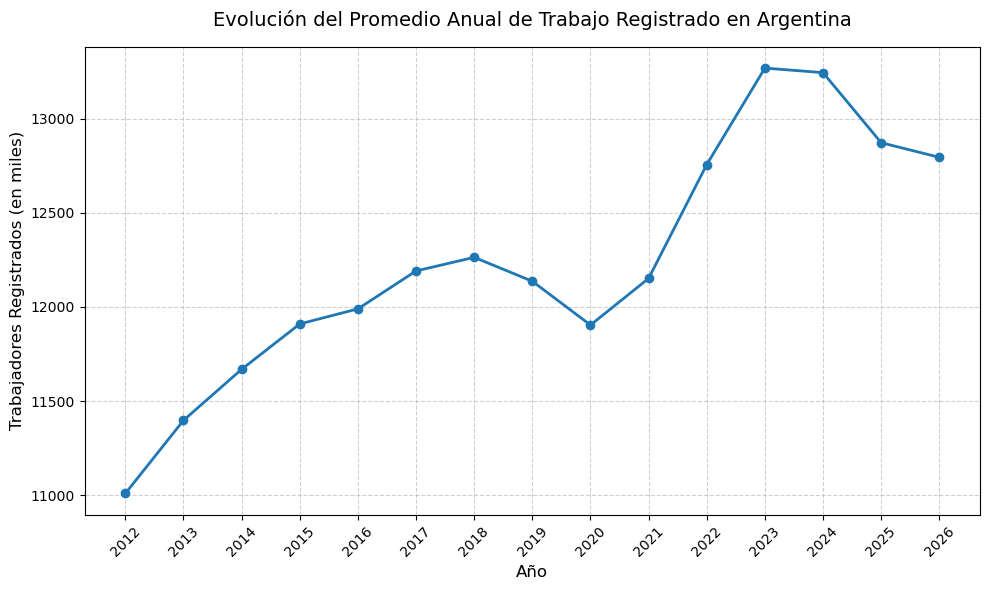

In [11]:
# ==============================================================================
# 1 - Evolución del Promedio Anual de Trabajo Registrado en Argentina
# ==============================================================================

# Leer la pestaña relevante
df = pd.read_excel(excel_file, sheet_name='T.1', header=2)

# Renombrar columnas
df.columns = [
    'Fecha_Raw',
    'Serie_Original',
    'Serie_Desestacionalizada',
    'Indice_Original',
    'Indice_Desestacionalizado',
    'Volver',
]

# Filtrar filas vacías
df = df.dropna(subset=['Fecha_Raw', 'Serie_Original'])

# Función para extraer el año de forma flexible
def extraer_anio(val):
  if pd.isna(val):
    return None
  if isinstance(val, (pd.Timestamp, datetime)):
    return val.year

  val_str = str(val).strip().lower()
  months = {
      'ene': 1,
      'feb': 2,
      'mar': 3,
      'abr': 4,
      'may': 5,
      'jun': 6,
      'jul': 7,
      'ago': 8,
      'sep': 9,
      'oct': 10,
      'nov': 11,
      'dic': 12,
  }

  for m_name in months:
    if m_name in val_str:
      parts = val_str.replace('*', '').split('-')
      for p in parts:
        p_clean = p.strip()
        if p_clean.isdigit() and len(p_clean) == 2:
          yr = int(p_clean)
          return yr + (2000 if yr < 50 else 1900)
        elif p_clean.isdigit() and len(p_clean) == 4:
          return int(p_clean)
  try:
    return pd.to_datetime(val).year
  except:
    return None


# Extraer el año y calcular el promedio anual
df['Año'] = df['Fecha_Raw'].apply(extraer_anio)
df = df.dropna(subset=['Año'])
df['Año'] = df['Año'].astype(int)

df_anual = df.groupby('Año')['Serie_Original'].mean().reset_index()

# GENERACIÓN DEL GRÁFICO DE LÍNEAS

plt.figure(figsize=(10, 6))
plt.plot(
    df_anual['Año'],
    df_anual['Serie_Original'],
    marker='o',
    color='tab:blue',
    linestyle='-',
    linewidth=2,
)

plt.title(
    'Evolución del Promedio Anual de Trabajo Registrado en Argentina',
    fontsize=14,
    pad=15,
)
plt.xlabel('Año', fontsize=12)
plt.ylabel('Trabajadores Registrados (en miles)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(df_anual['Año'], rotation=45)
plt.tight_layout()
plt.show()

C:\Users\outlet\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:79: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():
C:\Users\outlet\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:79: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():


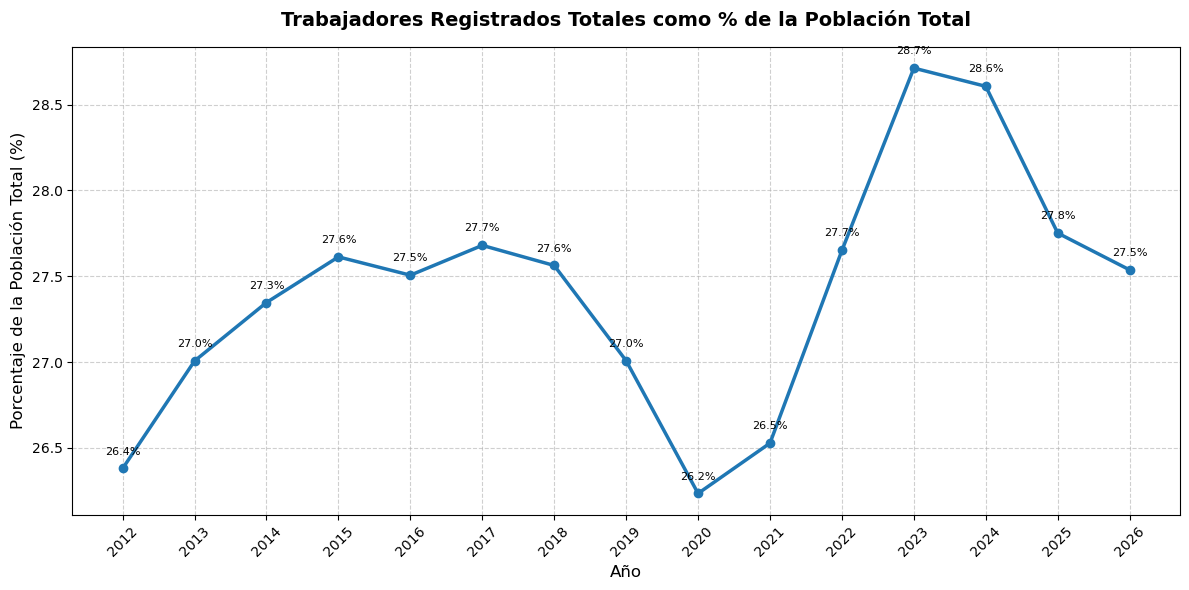

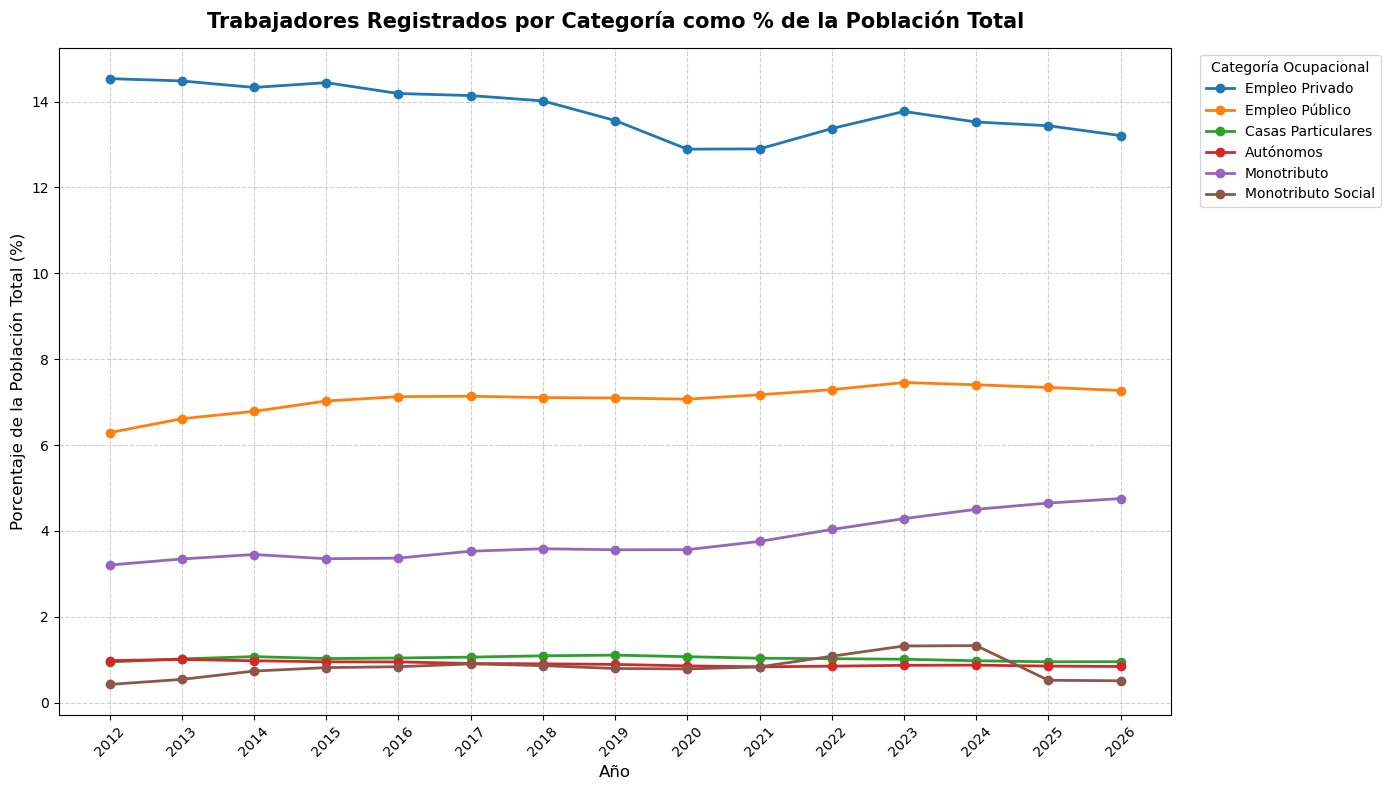

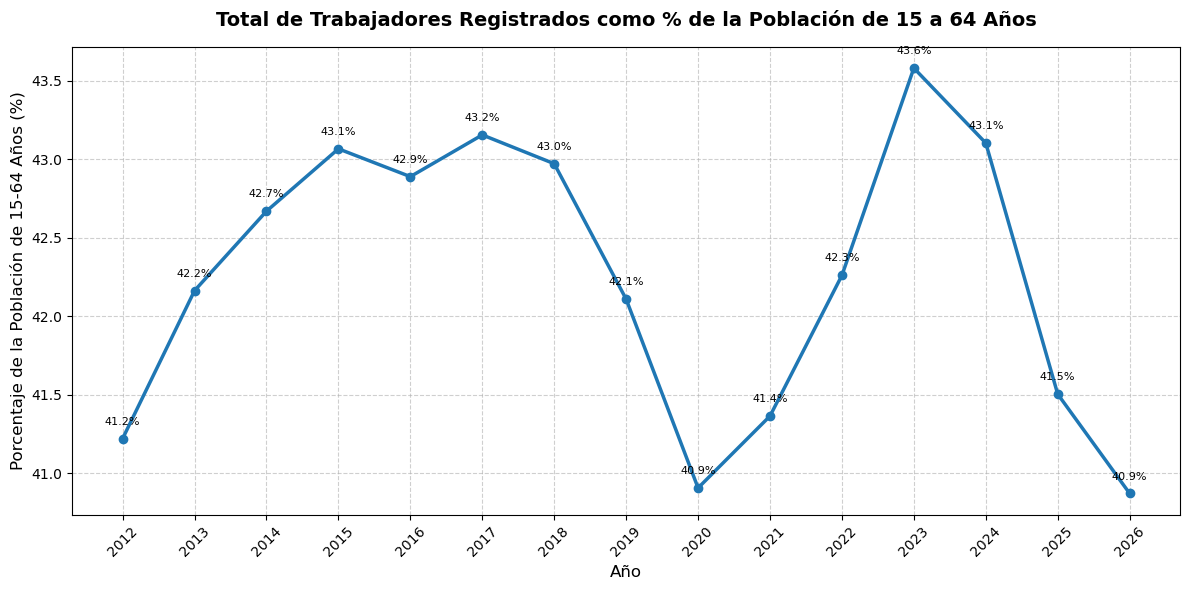

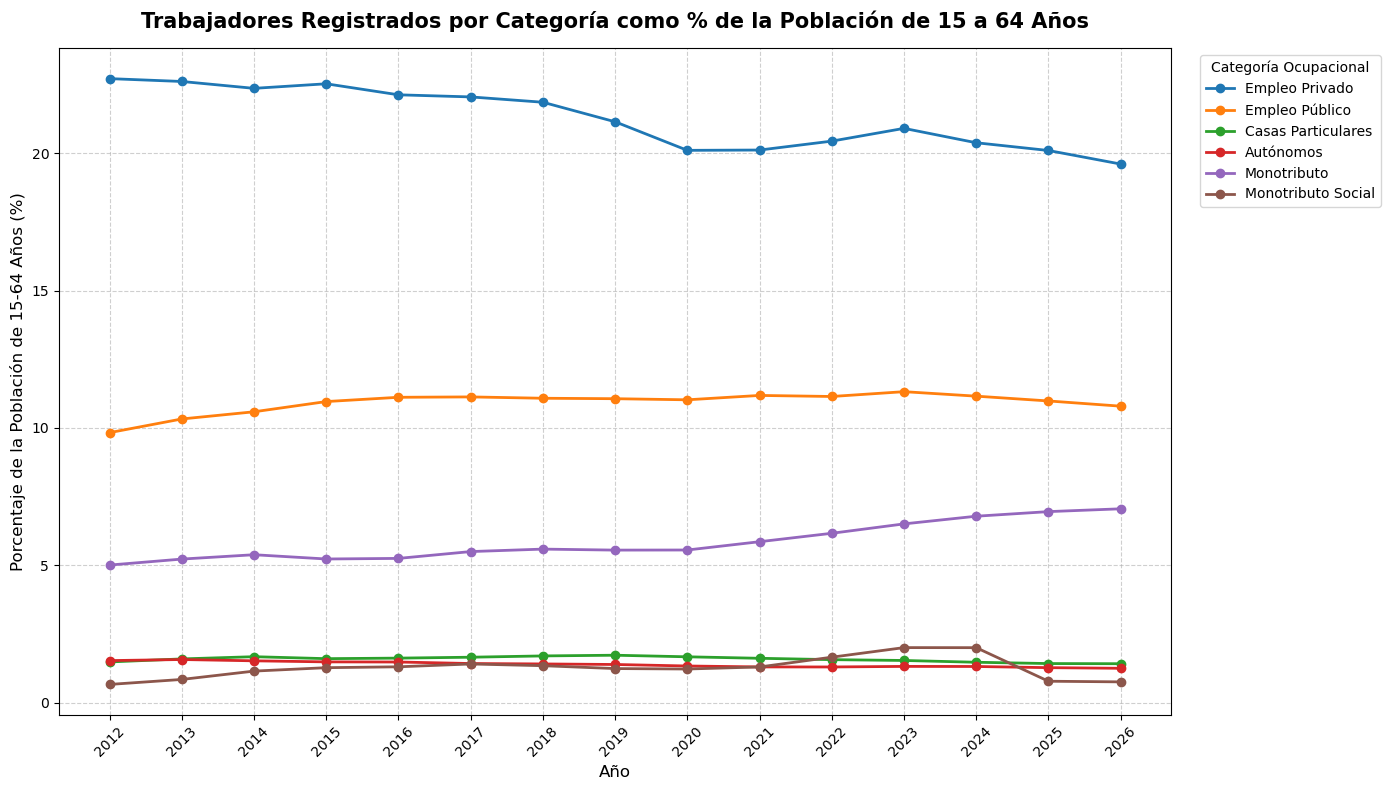

In [23]:
# ==============================================================================
# 1. PROCESAMIENTO DE POBLACIÓN (Total y 15-64 años)
# ==============================================================================
grupos_15_64 = [f"{i}-{i+4}" for i in range(15, 65, 5)]

df_pob_total = (
    df_poblacion_unificada.groupby('Año')['Poblacion']
    .sum()
    .reset_index(name='Poblacion_Total')
)
df_pob_15_64 = (
    df_poblacion_unificada[
        df_poblacion_unificada['Grupo_Edad'].isin(grupos_15_64)
    ]
    .groupby('Año')['Poblacion']
    .sum()
    .reset_index(name='Pob_15_64')
)

# ==============================================================================
# 2. PROCESAMIENTO DE TRABAJO REGISTRADO (Hojas T.1 y T.2.1)
# ==============================================================================
excel_trabajo = pd.ExcelFile('trabajoregistrado_2607_estadisticas.xlsx')

# Hoja T.1 (Totales)
df_t1 = pd.read_excel(excel_trabajo, sheet_name='T.1', header=2)
df_t1.columns = [
    'Fecha_Raw',
    'Serie_Original',
    'Serie_Desestacionalizada',
    'Indice_Original',
    'Indice_Desestacionalizado',
    'Volver',
][: len(df_t1.columns)]
df_t1 = df_t1.dropna(subset=['Fecha_Raw', 'Serie_Original'])
df_t1['Año'] = df_t1['Fecha_Raw'].apply(extraer_anio)
df_t1_anual = df_t1.groupby('Año')['Serie_Original'].mean().reset_index()
df_t1_anual['Trabajadores_Abs'] = df_t1_anual['Serie_Original'] * 1000

# Hoja T.2.1 (Por categorías)
df_t21 = pd.read_excel(excel_trabajo, sheet_name='T.2.1', header=1)
df_t21.columns = [
    'Fecha_Raw',
    'Privado',
    'Publico',
    'Casas_Particulares',
    'Autonomos',
    'Monotributo',
    'Monotributo_Social',
    'Total',
    'Extra',
][: len(df_t21.columns)]
df_t21 = df_t21.dropna(subset=['Fecha_Raw', 'Privado'])
df_t21['Año'] = df_t21['Fecha_Raw'].apply(extraer_anio)

categorias = [
    'Privado',
    'Publico',
    'Casas_Particulares',
    'Autonomos',
    'Monotributo',
    'Monotributo_Social',
    'Total',
]
df_t21[categorias] = (
    df_t21[categorias].apply(pd.to_numeric, errors='coerce') * 1000
)
df_t21_anual = df_t21.groupby('Año')[categorias].mean().reset_index()

# ==============================================================================
# 3. CRUCES DE DATOS (Población Total vs. Población 15-64)
# ==============================================================================
df_m_tot = pd.merge(df_pob_total, df_t1_anual, on='Año')
df_m_tot['Porcentaje'] = (
    df_m_tot['Trabajadores_Abs'] / df_m_tot['Poblacion_Total']
) * 100

df_m_tot_cats = pd.merge(df_pob_total, df_t21_anual, on='Año')
cats_, cats_tot = categorias[:-1], categorias[-1]
for c in categorias:
  df_m_tot_cats[f'Pct_{c}'] = (
      df_m_tot_cats[c] / df_m_tot_cats['Poblacion_Total']
  ) * 100

df_m_1564 = pd.merge(df_pob_15_64, df_t21_anual, on='Año')
for c in categorias:
  df_m_1564[f'Pct_{c}'] = (df_m_1564[c] / df_m_1564['Pob_15_64']) * 100

# Estilos comunes
nombres_legibles = {
    'Privado': 'Empleo Privado',
    'Publico': 'Empleo Público',
    'Casas_Particulares': 'Casas Particulares',
    'Autonomos': 'Autónomos',
    'Monotributo': 'Monotributo',
    'Monotributo_Social': 'Monotributo Social',
}
colores = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']


# Función auxiliar para graficar líneas
def plot_linea(df, x_col, y_col, titulo, ylabel):
  plt.figure(figsize=(12, 6))
  plt.plot(
      df[x_col], df[y_col], marker='o', color='tab:blue', linewidth=2.5
  )
  plt.title(titulo, fontsize=14, fontweight='bold', pad=15)
  plt.xlabel('Año', fontsize=12)
  plt.ylabel(ylabel, fontsize=12)
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.xticks(df[x_col], rotation=45)
  for yr, pct in zip(df[x_col], df[y_col]):
    plt.annotate(
        f'{pct:.1f}%',
        (yr, pct),
        textcoords='offset points',
        xytext=(0, 10),
        ha='center',
        fontsize=8,
    )
  plt.tight_layout()
  plt.show()


def plot_multilineas(df, x_col, cats, titulo, ylabel):
  plt.figure(figsize=(14, 8))
  for cat, col in zip(cats, colores):
    plt.plot(
        df[x_col],
        df[f'Pct_{cat}'],
        marker='o',
        linewidth=2,
        label=nombres_legibles[cat],
        color=col,
    )
  plt.title(titulo, fontsize=15, fontweight='bold', pad=15)
  plt.xlabel('Año', fontsize=12)
  plt.ylabel(ylabel, fontsize=12)
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.xticks(df[x_col], rotation=45)
  plt.legend(
      title='Categoría Ocupacional', bbox_to_anchor=(1.02, 1), loc='upper left'
  )
  plt.tight_layout()
  plt.show()


# ==============================================================================
# 4. GENERACIÓN DE LOS 4 GRÁFICOS
# ==============================================================================
# Gráfico 1: Totales como % de Población Total
plot_linea(
    df_m_tot,
    'Año',
    'Porcentaje',
    'Trabajadores Registrados Totales como % de la Población Total',
    'Porcentaje de la Población Total (%)',
)

# Gráfico 2: Categorías como % de Población Total
plot_multilineas(
    df_m_tot_cats,
    'Año',
    cats_,
    'Trabajadores Registrados por Categoría como % de la Población Total',
    'Porcentaje de la Población Total (%)',
)

# Gráfico 3: Totales como % de Población 15-64
plot_linea(
    df_m_1564,
    'Año',
    'Pct_Total',
    'Total de Trabajadores Registrados como % de la Población de 15 a 64 Años',
    'Porcentaje de la Población de 15-64 Años (%)',
)

# Gráfico 4: Categorías como % de Población 15-64
plot_multilineas(
    df_m_1564,
    'Año',
    cats_,
    'Trabajadores Registrados por Categoría como % de la Población de 15 a 64 Años',
    'Porcentaje de la Población de 15-64 Años (%)',
)

C:\Users\outlet\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:79: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():


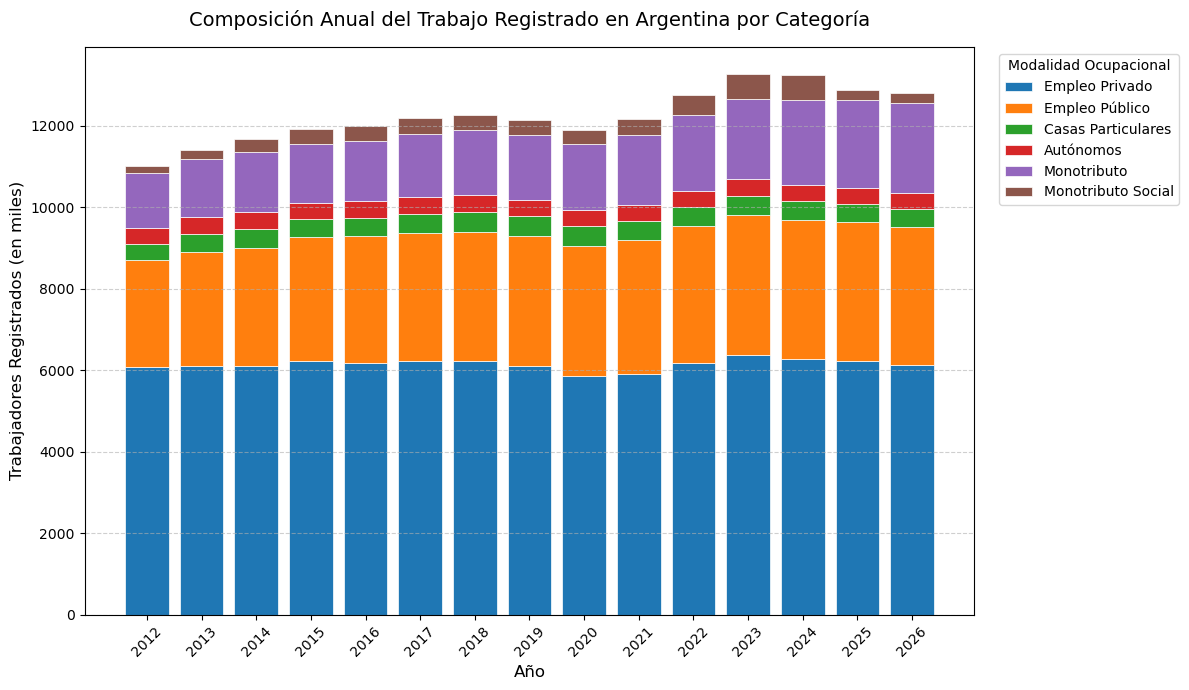

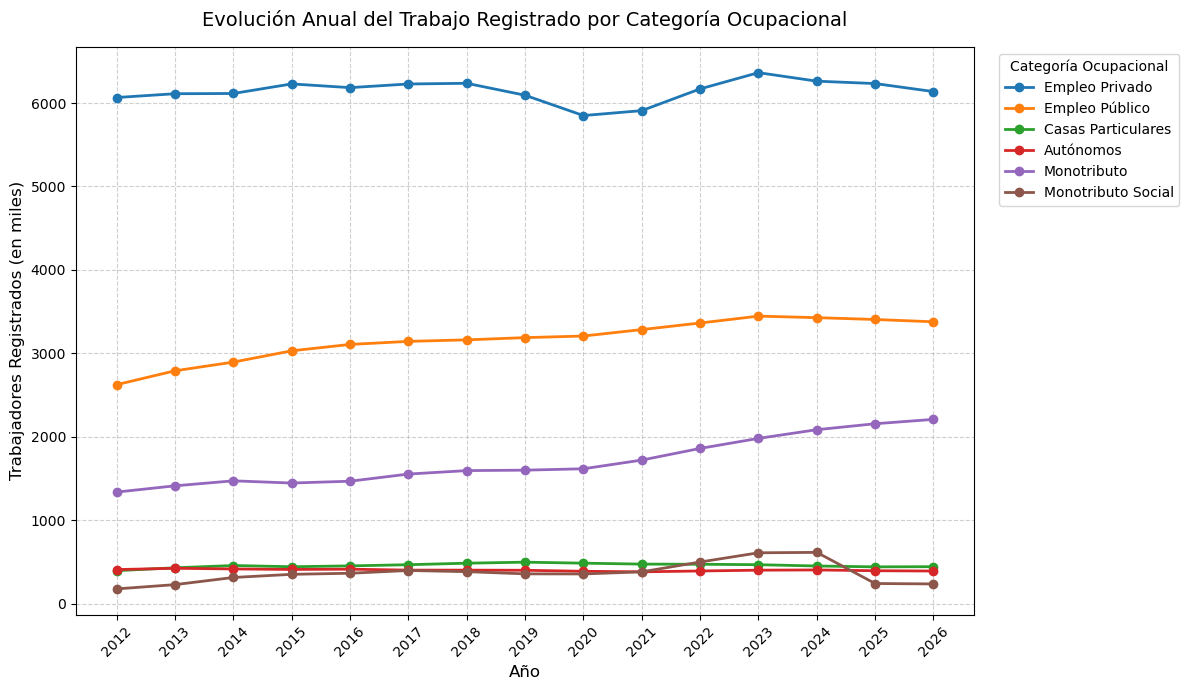

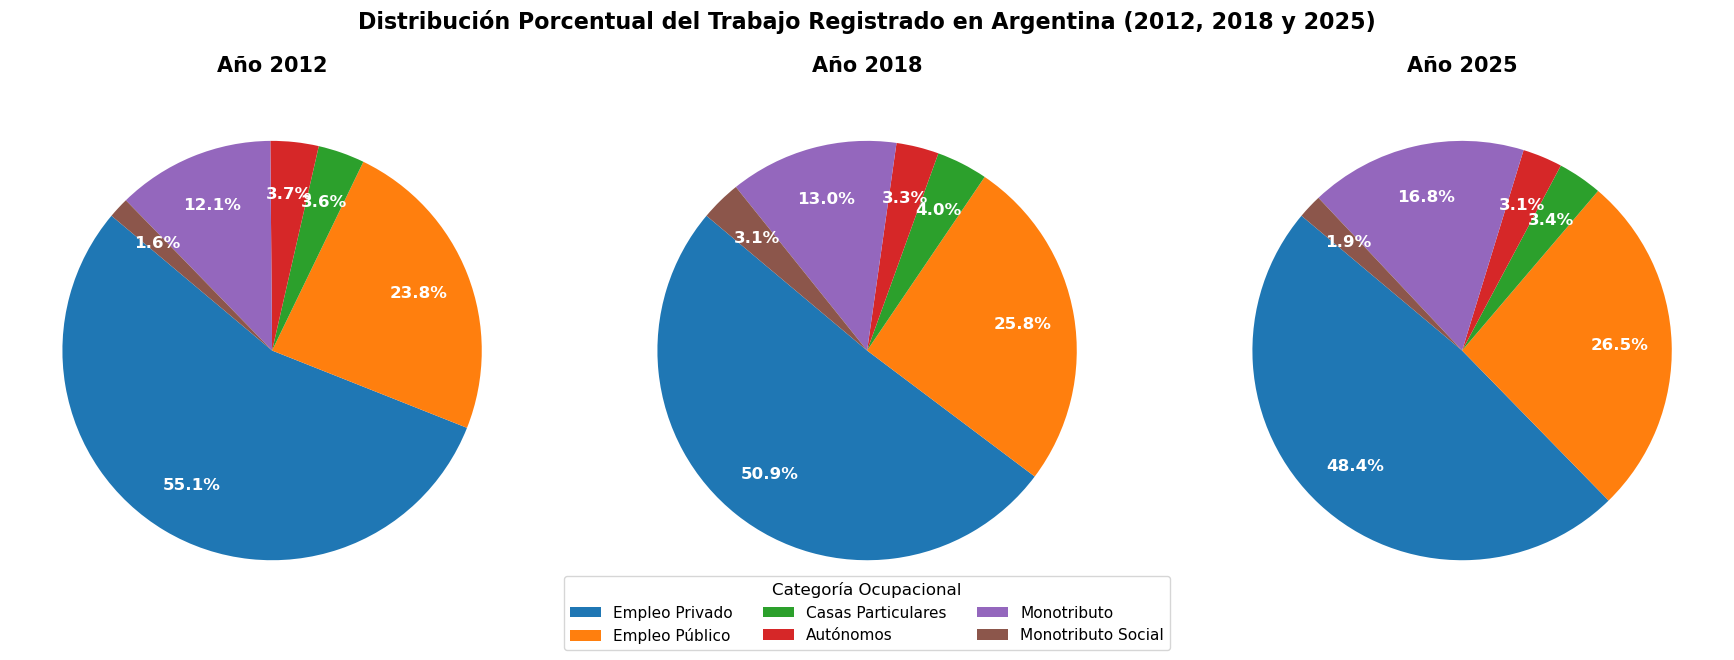

In [24]:
# ==============================================================================
# 1. CARGA Y PROCESAMIENTO ÚNICO DE DATOS (Pestaña T.2.1)
# ==============================================================================
df = pd.read_excel(excel_file, sheet_name='T.2.1', header=1)

df.columns = [
    'Fecha_Raw',
    'Privado',
    'Publico',
    'Casas_Particulares',
    'Autonomos',
    'Monotributo',
    'Monotributo_Social',
    'Total',
    'Extra',
][: len(df.columns)]

df = df.dropna(subset=['Fecha_Raw', 'Privado'])


def extraer_anio(val):
  if pd.isna(val):
    return None
  if isinstance(val, (pd.Timestamp, datetime)):
    return val.year
  val_str = str(val).strip().lower()
  for m in [
      'ene',
      'feb',
      'mar',
      'abr',
      'may',
      'jun',
      'jul',
      'ago',
      'sep',
      'oct',
      'nov',
      'dic',
  ]:
    if m in val_str:
      parts = [
          p.strip()
          for p in val_str.replace('*', '').split('-')
          if p.strip().isdigit()
      ]
      if parts:
        yr = int(parts[0])
        return yr + (2000 if yr < 50 else 1900) if len(parts[0]) == 2 else yr
  try:
    return pd.to_datetime(val).year
  except:
    return None


df['Año'] = df['Fecha_Raw'].apply(extraer_anio)
df = df.dropna(subset=['Año'])
df['Año'] = df['Año'].astype(int)

categorias = [
    'Privado',
    'Publico',
    'Casas_Particulares',
    'Autonomos',
    'Monotributo',
    'Monotributo_Social',
]
for cat in categorias:
  df[cat] = pd.to_numeric(df[cat], errors='coerce')

# DataFrame anual agrupado (con índice 'Año' y formato estándar)
df_anual = df.groupby('Año')[categorias].mean().reset_index()

# Paleta de colores y nombres legibles comunes
colores = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
nombres_legibles = [
    'Empleo Privado',
    'Empleo Público',
    'Casas Particulares',
    'Autónomos',
    'Monotributo',
    'Monotributo Social',
]
anos = df_anual['Año']


# ==============================================================================
# 2. GRÁFICO 1: BARRAS VERTICALES APILADAS
# ==============================================================================
fig, ax = plt.subplots(figsize=(12, 7))
bottom = None

for i, cat in enumerate(categorias):
  valores = df_anual[cat]
  ax.bar(
      anos,
      valores,
      bottom=bottom,
      label=nombres_legibles[i],
      color=colores[i],
      edgecolor='white',
      linewidth=0.5,
  )
  bottom = valores.copy() if bottom is None else bottom + valores

ax.set_title(
    'Composición Anual del Trabajo Registrado en Argentina por Categoría',
    fontsize=14,
    pad=15,
)
ax.set_xlabel('Año', fontsize=12)
ax.set_ylabel('Trabajadores Registrados (en miles)', fontsize=12)
ax.grid(axis='y', linestyle='--', alpha=0.6)
plt.xticks(anos, rotation=45)
ax.legend(title='Modalidad Ocupacional', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()


# ==============================================================================
# 3. GRÁFICO 2: LÍNEAS DE EVOLUCIÓN POR CATEGORÍA
# ==============================================================================
plt.figure(figsize=(12, 7))

for i, cat in enumerate(categorias):
  plt.plot(
      anos,
      df_anual[cat],
      marker='o',
      linewidth=2,
      label=nombres_legibles[i],
      color=colores[i],
  )

plt.title(
    'Evolución Anual del Trabajo Registrado por Categoría Ocupacional',
    fontsize=14,
    pad=15,
)
plt.xlabel('Año', fontsize=12)
plt.ylabel('Trabajadores Registrados (en miles)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(anos, rotation=45)
plt.legend(title='Categoría Ocupacional', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()


# ==============================================================================
# 4. GRÁFICO 3: TRES GRÁFICOS CIRCULARES (2012, 2018 y 2025)
# ==============================================================================
ANIOS_A_GRAFICAR = [2012, 2018, 2025]
df_anual_indexed = df_anual.set_index('Año')
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, anio in enumerate(ANIOS_A_GRAFICAR):
  ax = axes[i]
  if anio in df_anual_indexed.index:
    valores = df_anual_indexed.loc[anio]
    wedges, texts, autotexts = ax.pie(
        valores,
        labels=None,
        autopct='%1.1f%%',
        startangle=140,
        colors=colores,
        pctdistance=0.75,
        textprops=dict(color='white', fontweight='bold', fontsize=12),
    )
    ax.set_title(f'Año {anio}', fontsize=15, fontweight='bold', pad=12)
  else:
    ax.text(
        0.5,
        0.5,
        f'Sin datos para {anio}',
        ha='center',
        va='center',
        transform=ax.transAxes,
        fontsize=12,
    )

fig.legend(
    wedges,
    nombres_legibles,
    title='Categoría Ocupacional',
    loc='lower center',
    bbox_to_anchor=(0.5, -0.05),
    ncol=3,
    fontsize=11,
    title_fontsize=12,
)
plt.suptitle(
    'Distribución Porcentual del Trabajo Registrado en Argentina (2012, 2018'
    ' y 2025)',
    fontsize=16,
    fontweight='bold',
    y=1.03,
)

plt.tight_layout()
plt.show()

C:\Users\outlet\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:79: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():


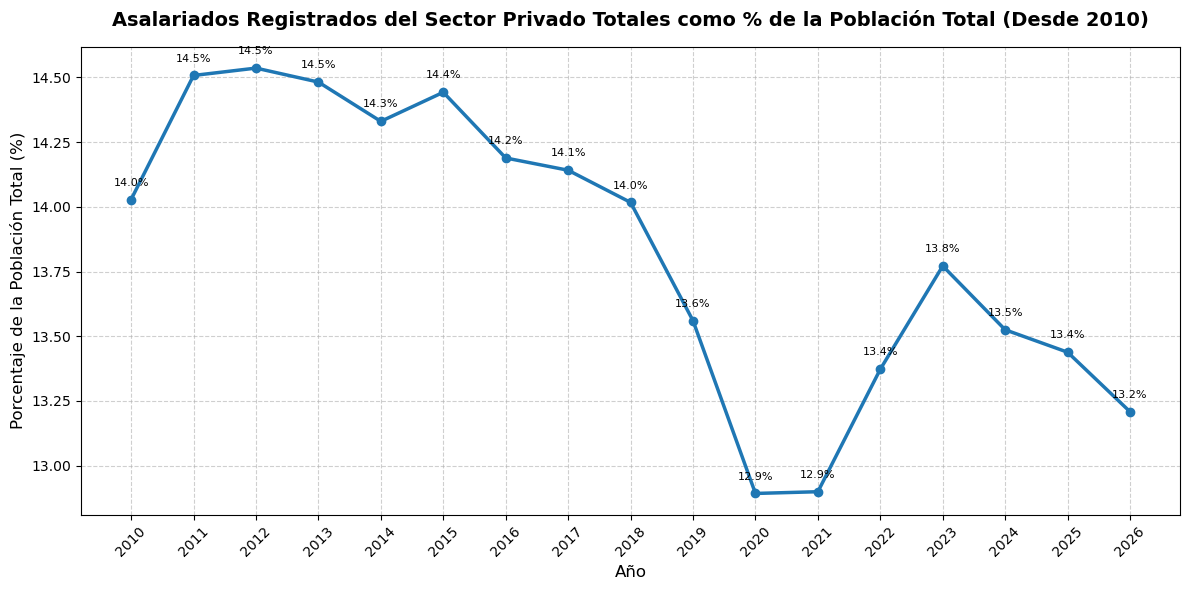

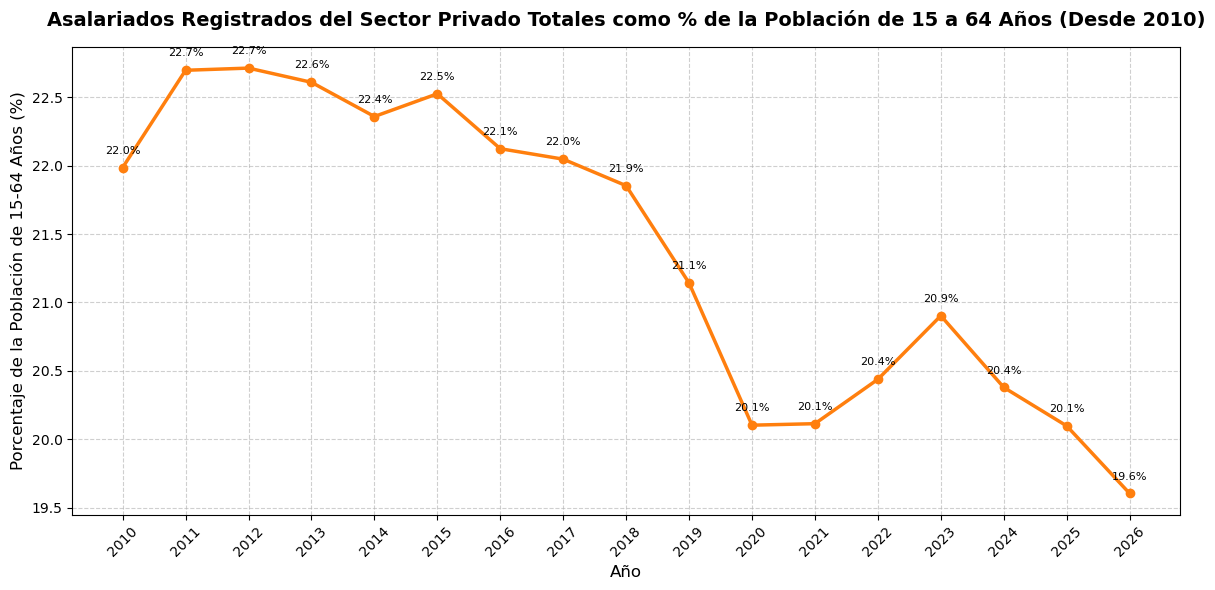

In [27]:
# ==============================================================================
# 1. PREPARACIÓN DE DENOMINADORES DEMOGRÁFICOS (Población Total y 15-64 años)
# ==============================================================================
grupos_15_64 = [f'{i}-{i+4}' for i in range(15, 65, 5)]

df_pob_total = (
    df_poblacion_unificada.groupby('Año')['Poblacion']
    .sum()
    .reset_index(name='Poblacion_Total')
)
df_pob_15_64 = (
    df_poblacion_unificada[
        df_poblacion_unificada['Grupo_Edad'].isin(grupos_15_64)
    ]
    .groupby('Año')['Poblacion']
    .sum()
    .reset_index(name='Pob_15_64')
)

# ==============================================================================
# 2. PROCESAMIENTO DE TRABAJO ASALARIADO REGISTRADO (Pestaña A.1 / A1)
# ==============================================================================
excel_trabajo = pd.ExcelFile('trabajoregistrado_2607_estadisticas.xlsx')

# Intentar leer la pestaña 'A.1' (o 'A1' según el archivo exacto)
sheet_name_a1 = 'A.1' if 'A.1' in excel_trabajo.sheet_names else 'A1'
df_a1 = pd.read_excel(excel_trabajo, sheet_name=sheet_name_a1, header=2)

df_a1.columns = [
    'Fecha_Raw',
    'Serie_Original',
    'Serie_Desestacionalizada',
    'Indice_Original',
    'Indice_Desestacionalizado',
    'Volver',
][: len(df_a1.columns)]
df_a1 = df_a1.dropna(subset=['Fecha_Raw', 'Serie_Original'])
df_a1['Año'] = df_a1['Fecha_Raw'].apply(extraer_anio)

df_a1_anual = df_a1.groupby('Año')['Serie_Original'].mean().reset_index()
df_a1_anual['Trabajadores_Abs'] = df_a1_anual['Serie_Original'] * 1000

# ==============================================================================
# 3. CRUCES Y CÁLCULOS PORCENTUALES
# ==============================================================================
df_m_tot = pd.merge(df_pob_total, df_a1_anual, on='Año', how='inner')
df_m_tot['Pct_Total'] = (
    df_m_tot['Trabajadores_Abs'] / df_m_tot['Poblacion_Total']
) * 100

df_m_1564 = pd.merge(df_pob_15_64, df_a1_anual, on='Año', how='inner')
df_m_1564['Pct_1564'] = (
    df_m_1564['Trabajadores_Abs'] / df_m_1564['Pob_15_64']
) * 100


# ==============================================================================
# 4. GENERACIÓN DE LOS 2 GRÁFICOS DE LÍNEAS
# ==============================================================================

# Gráfico 1: Asalariados Registrados como % de la Población Total (desde 2009)
plt.figure(figsize=(12, 6))
plt.plot(
    df_m_tot['Año'],
    df_m_tot['Pct_Total'],
    marker='o',
    color='tab:blue',
    linewidth=2.5,
    markersize=6,
)
plt.title(
    'Asalariados Registrados del Sector Privado Totales como % de la Población Total (Desde 2010)',
    fontsize=14,
    pad=15,
    fontweight='bold',
)
plt.xlabel('Año', fontsize=12)
plt.ylabel('Porcentaje de la Población Total (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(df_m_tot['Año'], rotation=45)

for yr, pct in zip(df_m_tot['Año'], df_m_tot['Pct_Total']):
  plt.annotate(
      f'{pct:.1f}%',
      (yr, pct),
      textcoords='offset points',
      xytext=(0, 10),
      ha='center',
      fontsize=8,
  )

plt.tight_layout()
plt.show()

# Gráfico 2: Asalariados Registrados como % de la Población de 15 a 64 años (desde 2009)
plt.figure(figsize=(12, 6))
plt.plot(
    df_m_1564['Año'],
    df_m_1564['Pct_1564'],
    marker='o',
    color='tab:orange',
    linewidth=2.5,
    markersize=6,
)
plt.title(
    'Asalariados Registrados del Sector Privado Totales como % de la Población de 15 a 64 Años'
    ' (Desde 2010)',
    fontsize=14,
    pad=15,
    fontweight='bold',
)
plt.xlabel('Año', fontsize=12)
plt.ylabel('Porcentaje de la Población de 15-64 Años (%)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(df_m_1564['Año'], rotation=45)

for yr, pct in zip(df_m_1564['Año'], df_m_1564['Pct_1564']):
  plt.annotate(
      f'{pct:.1f}%',
      (yr, pct),
      textcoords='offset points',
      xytext=(0, 10),
      ha='center',
      fontsize=8,
  )

plt.tight_layout()
plt.show()

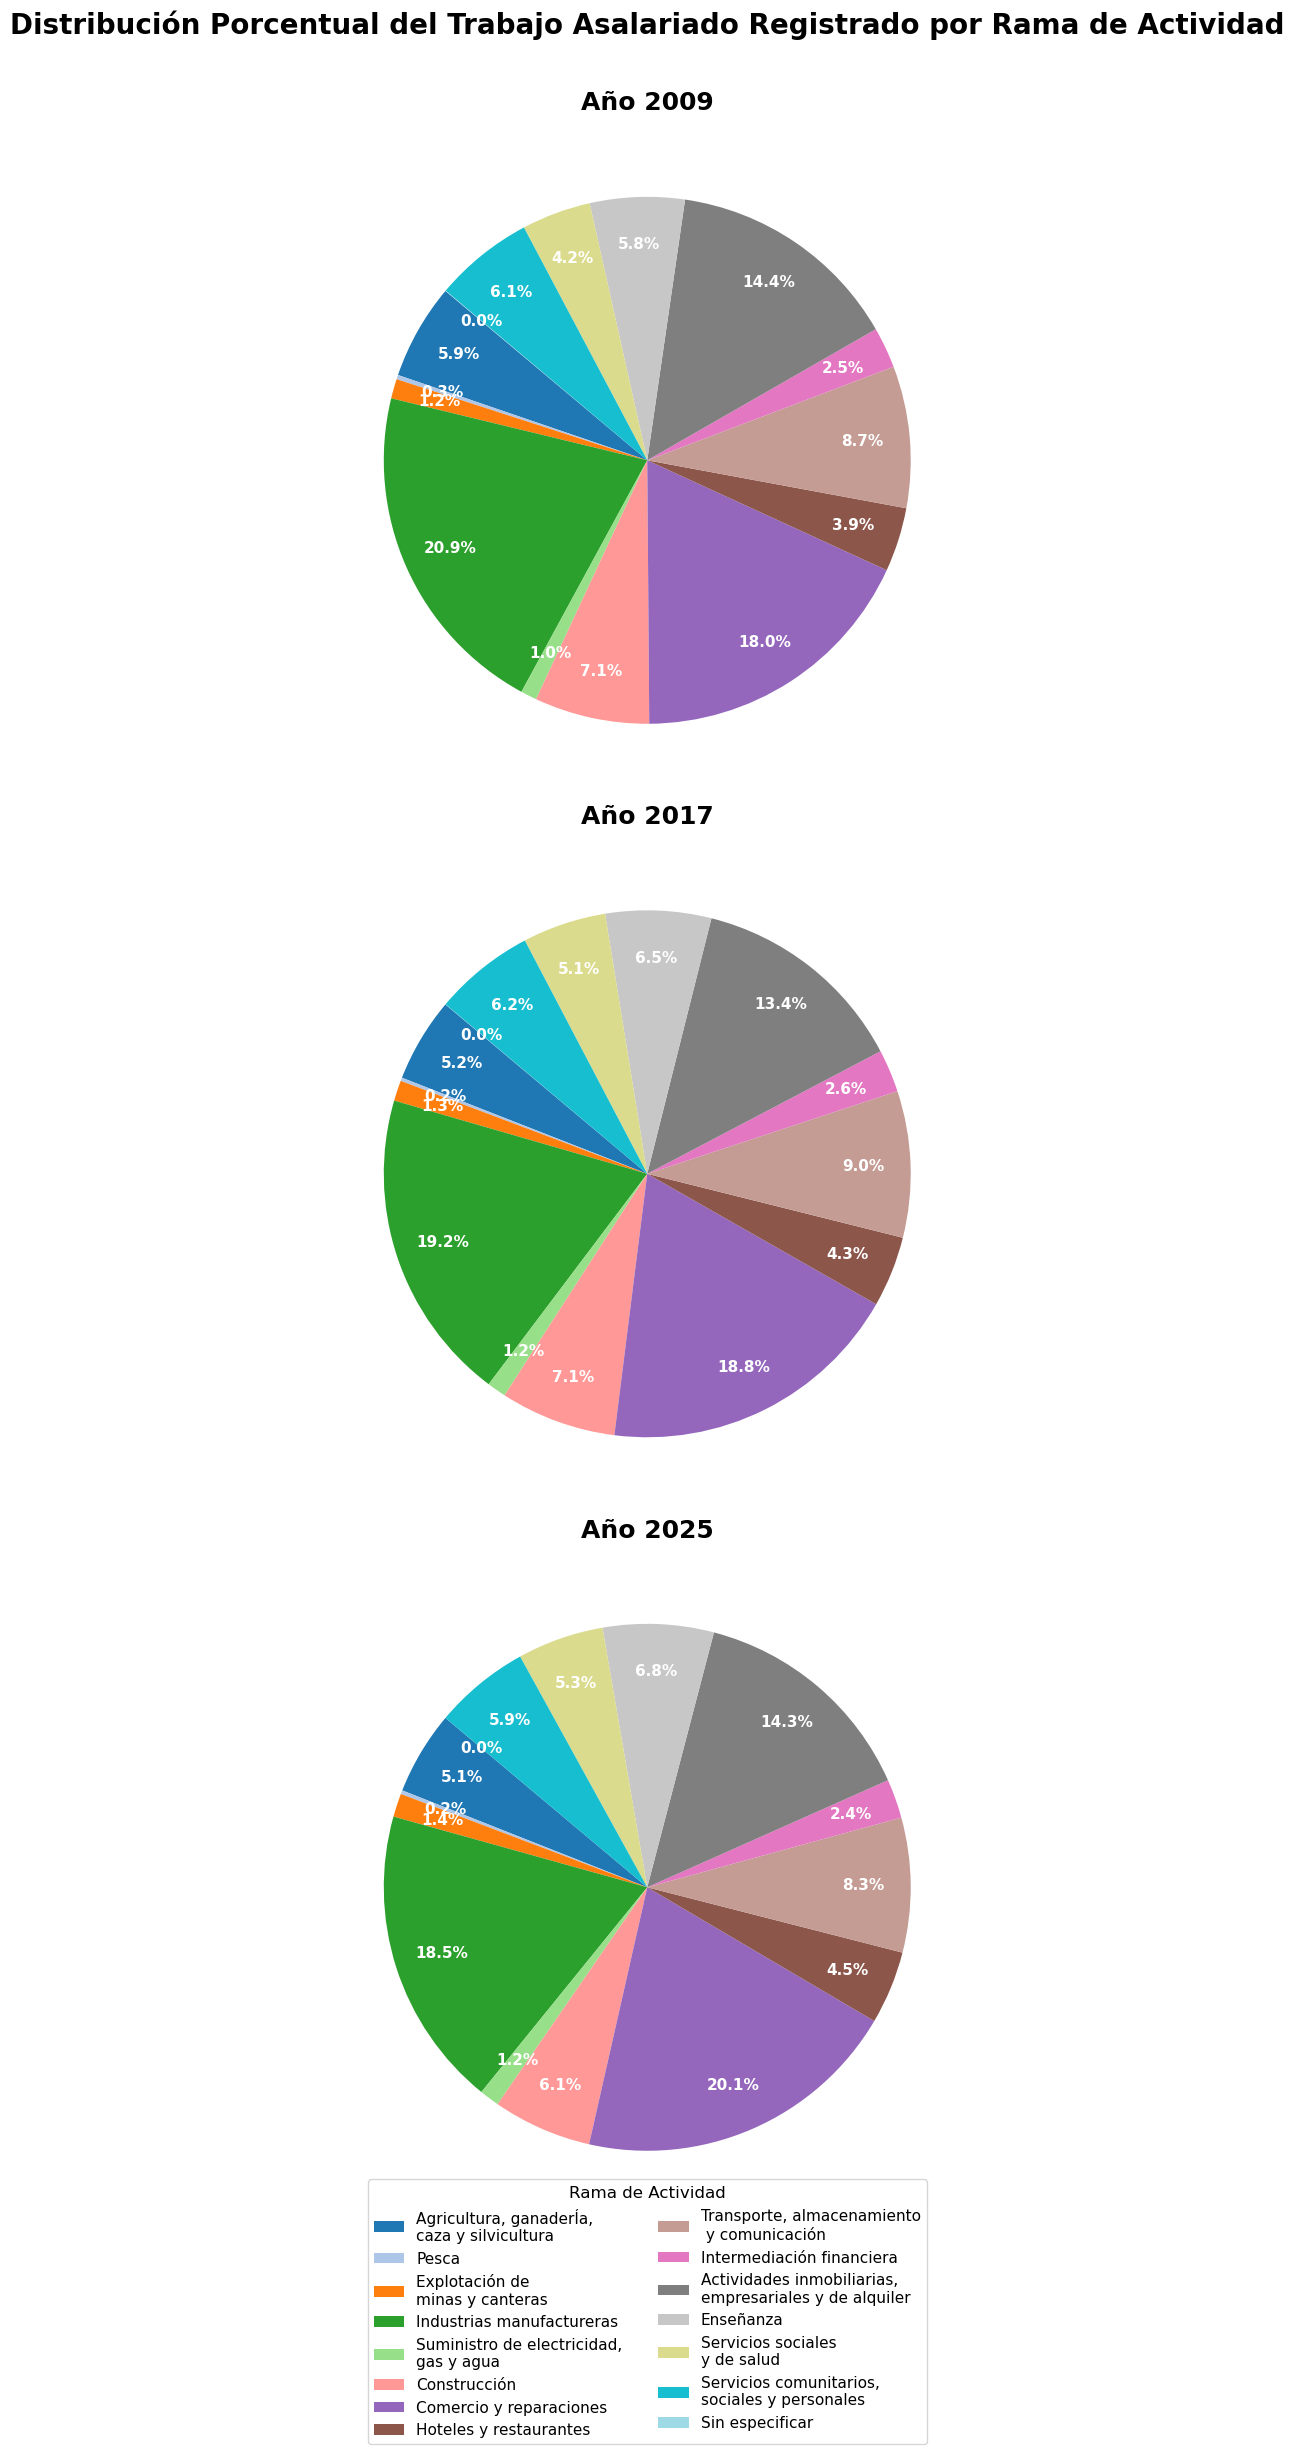

In [36]:
# ==============================================================================
# 3 GRÁFICOS CIRCULARES VERTICALES: DISTRIBUCIÓN POR RAMA DE ACTIVIDAD (A.2.1)
# ==============================================================================
ANIOS_RAMAS = [2009, 2017, 2025]  # O 2026 según corresponda en tus datos

# Crear figura vertical: 3 filas, 1 columna (con tamaño grande para visibilidad)
fig, axes = plt.subplots(3, 1, figsize=(10, 22))

colores_ramas = cm.tab20(np.linspace(0, 1, len(ramas_cols)))
wedges = None

for i, anio in enumerate(ANIOS_RAMAS):
  ax = axes[i]
  # Si el año exacto no está, buscar el más cercano disponible en el índice
  anio_a_usar = (
      anio
      if anio in df_a21_anual.index
      else min(df_a21_anual.index, key=lambda x: abs(x - anio))
  )

  if anio_a_usar in df_a21_anual.index:
    valores = df_a21_anual.loc[anio_a_usar].dropna()
    valores = valores[valores > 0]

    wedges, texts, autotexts = ax.pie(
        valores,
        labels=None,
        autopct='%1.1f%%',
        startangle=140,
        colors=colores_ramas[: len(valores)],
        pctdistance=0.82,
        textprops=dict(
            color='white', fontweight='bold', fontsize=11
        ),  # % más grandes
    )
    ax.set_title(
        f'Año {anio_a_usar}', fontsize=18, fontweight='bold', pad=15
    )
  else:
    ax.text(
        0.5,
        0.5,
        f'Sin datos para {anio}',
        ha='center',
        va='center',
        transform=ax.transAxes,
        fontsize=14,
    )

# Leyenda unificada abajo, organizada en columnas para que entren todas las categorías
if wedges is not None:
  fig.legend(
      wedges,
      ramas_cols[: len(wedges)],
      title='Rama de Actividad',
      loc='lower center',
      bbox_to_anchor=(0.5, -0.10),
      ncol=2,  # Organizado en 2 columnas debajo de los gráficos
      fontsize=11,
      title_fontsize=12,
  )

plt.suptitle(
    'Distribución Porcentual del Trabajo Asalariado Registrado por Rama de'
    ' Actividad',
    fontsize=20,
    fontweight='bold',
    y=1.01,
)

plt.tight_layout()
plt.show()

C:\Users\outlet\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:79: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():
C:\Users\outlet\anaconda3\Lib\site-packages\openpyxl\worksheet\_read_only.py:79: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():


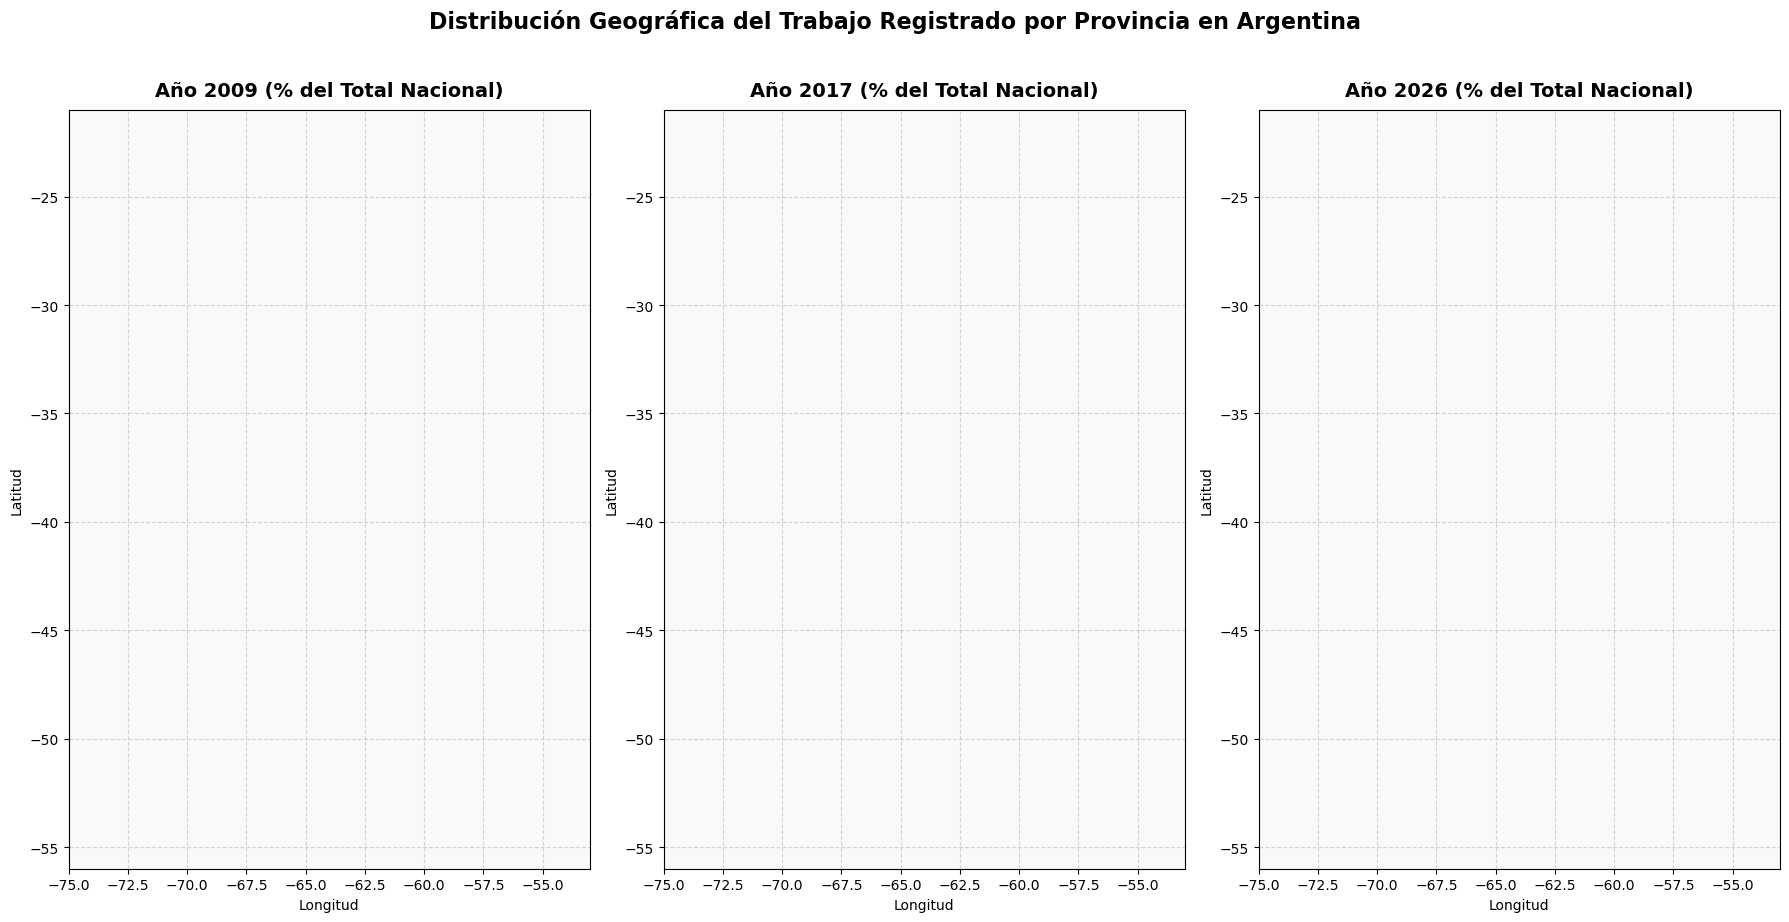

In [40]:
# ==============================================================================
# MAPAS PROVINCIALES: TRABAJO REGISTRADO (Pestañas A.5.1 y A.1)
# ==============================================================================
excel_trabajo = pd.ExcelFile('trabajoregistrado_2607_estadisticas.xlsx')

# 1. Leer Total Nacional desde la pestaña A.1
df_a1 = pd.read_excel(excel_trabajo, sheet_name='A.1', header=2)
df_a1.columns = [
    'Fecha_Raw',
    'Serie_Original',
    'Serie_Desestacionalizada',
    'Indice_Original',
    'Indice_Desestacionalizado',
    'Volver',
][: len(df_a1.columns)]
df_a1 = df_a1.dropna(subset=['Fecha_Raw', 'Serie_Original'])
df_a1['Año'] = df_a1['Fecha_Raw'].apply(extraer_anio)
df_a1_anual = (
    df_a1.groupby('Año')['Serie_Original'].mean().reset_index(name='Total_Nacional')
)
df_a1_anual['Total_Nacional'] = df_a1_anual['Total_Nacional'] * 1000

# 2. Leer Datos Provinciales desde la pestaña A.5.1
df_a51 = pd.read_excel(excel_trabajo, sheet_name='A.5.1', header=2)
df_a51 = df_a51.dropna(subset=[df_a51.columns[0]])
df_a51['Año'] = df_a51[df_a51.columns[0]].apply(extraer_anio)
df_a51 = df_a51.dropna(subset=['Año'])
df_a51['Año'] = df_a51['Año'].astype(int)

prov_cols = [c for c in df_a51.columns if c not in [df_a51.columns[0], 'Año']]

for col in prov_cols:
  df_a51[col] = pd.to_numeric(df_a51[col], errors='coerce')

df_a51_anual = (
    df_a51.groupby('Año')[prov_cols].mean().reset_index().set_index('Año')
)
df_mapa_data = pd.merge(df_a51_anual, df_a1_anual, on='Año', how='inner').set_index(
    'Año'
)

# 3. Diccionario exacto con coordenadas de las provincias
provincias_coords = {
    'BUENOS AIRES': (-36.67, -60.57),
    'CDAD. AUTÓNOMA DE BUENOS AIRES': (-34.60, -58.38),
    'CATAMARCA': (-28.46, -65.77),
    'CHACO': (-26.85, -60.76),
    'CHUBUT': (-43.29, -65.10),
    'CÓRDOBA': (-31.42, -64.18),
    'CORRIENTES': (-27.48, -58.83),
    'ENTRE RÍOS': (-32.02, -60.52),
    'FORMOSA': (-26.18, -58.17),
    'JUJUY': (-24.18, -65.30),
    'LA PAMPA': (-36.61, -64.28),
    'LA RIOJA': (-29.41, -66.85),
    'MENDOZA': (-32.89, -68.82),
    'MISIONES': (-26.87, -54.65),
    'NEUQUÉN': (-38.95, -68.05),
    'RÍO NEGRO': (-40.81, -63.00),
    'SALTA': (-24.78, -65.41),
    'SAN JUAN': (-31.53, -68.53),
    'SAN LUIS': (-33.30, -66.33),
    'SANTA CRUZ': (-51.62, -69.21),
    'SANTA FE': (-31.63, -60.70),
    'SANTIAGO DEL ESTERO': (-27.78, -64.26),
    'TIERRA DEL FUEGO': (-54.80, -68.30),
    'TUCUMÁN': (-26.80, -65.21),
}

# 4. Generación de los 3 mapas con límites geográficos fijos para Argentina
ANIOS_MAPA = [2009, 2017, 2026]
fig, axes = plt.subplots(1, 3, figsize=(18, 9))

for i, anio in enumerate(ANIOS_MAPA):
  ax = axes[i]
  anio_a_usar = (
      anio
      if anio in df_mapa_data.index
      else min(df_mapa_data.index, key=lambda x: abs(x - anio))
  )

  # Establecer límites geográficos fijos de Argentina para que el mapa no quede vacío
  ax.set_xlim(-75, -53)  # Longitudes de Argentina
  ax.set_ylim(-56, -21)  # Latitudes de Argentina

  if anio_a_usar in df_mapa_data.index:
    fila = df_mapa_data.loc[anio_a_usar]
    total_nac = fila['Total_Nacional']

    lats, lons, porcentajes, nombres = [], [], [], []
    for prov in prov_cols:
      prov_limpio = str(prov).split('/')[0].strip().upper()

      if prov_limpio in provincias_coords:
        val_prov = fila[prov]
        if pd.notna(val_prov) and total_nac > 0:
          pct = (val_prov / total_nac) * 100
          lat, lon = provincias_coords[prov_limpio]
          lats.append(lat)
          lons.append(lon)
          porcentajes.append(pct)
          nombres.append(prov_limpio)

    if lats:
      sizes = [
          p * 120 for p in porcentajes
      ]  # Tamaño ajustado para visualizar bien

      ax.scatter(
          lons,
          lats,
          s=sizes,
          c=porcentajes,
          cmap='Blues',
          alpha=0.85,
          edgecolors='black',
          linewidth=1.2,
      )

      for lon, lat, pct, nom in zip(lons, lats, porcentajes, nombres):
        if (
            pct > 3.0
            or 'BUENOS AIRES' in nom
            or 'CÓRDOBA' in nom
            or 'SANTA FE' in nom
        ):
          ax.text(
              lon,
              lat,
              f'{pct:.1f}%',
              fontsize=8,
              fontweight='bold',
              ha='center',
              va='center',
          )

    ax.set_title(
        f'Año {anio_a_usar} (% del Total Nacional)',
        fontsize=14,
        fontweight='bold',
        pad=10,
    )
    ax.set_xlabel('Longitud', fontsize=10)
    ax.set_ylabel('Latitud', fontsize=10)
    ax.set_facecolor('#f8f9fa')  # Fondo claro para contraste
    ax.grid(True, linestyle='--', alpha=0.5)
  else:
    ax.text(
        0.5,
        0.5,
        f'Sin datos para {anio}',
        ha='center',
        va='center',
        transform=ax.transAxes,
        fontsize=12,
    )

plt.suptitle(
    'Distribución Geográfica del Trabajo Registrado por Provincia en Argentina',
    fontsize=16,
    fontweight='bold',
    y=1.02,
)
plt.tight_layout()
plt.show()